In [10]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.preprocessing import split_columns, best_f1_threshold

d = joblib.load('../data/processed/split.joblib')
X_train, y_train, g_train = d['X_train'], d['y_train'], d['g_train']
num_cols, cat_cols = split_columns(X_train)
FIG = '../reports/figures/'

In [2]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

lr_pipe = Pipeline([
    ('pre', preprocess),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=3000)),
])

In [3]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {'clf__C': [0.001, 0.01, 0.1, 1, 10]}

lr_search = GridSearchCV(lr_pipe, param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
lr_search.fit(X_train, y_train, groups=g_train)

print('Best C:', lr_search.best_params_)
print('Best CV PR-AUC: {:.4f}'.format(lr_search.best_score_))
print('Refit time: {:.1f}s'.format(lr_search.refit_time_))

Best C: {'clf__C': 0.01}
Best CV PR-AUC: 0.2029
Refit time: 0.9s


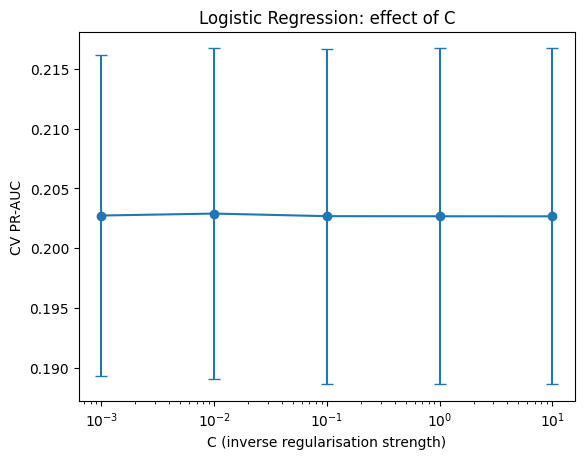

In [4]:
res = pd.DataFrame(lr_search.cv_results_)
plt.errorbar(res['param_clf__C'].astype(float), res['mean_test_score'],yerr=res['std_test_score'], marker='o', capsize=4)
plt.xscale('log')
plt.xlabel('C (inverse regularisation strength)')
plt.ylabel('CV PR-AUC')
plt.title('Logistic Regression: effect of C')
plt.savefig(FIG + '03_lr_C.png', dpi=150, bbox_inches='tight')
plt.show()

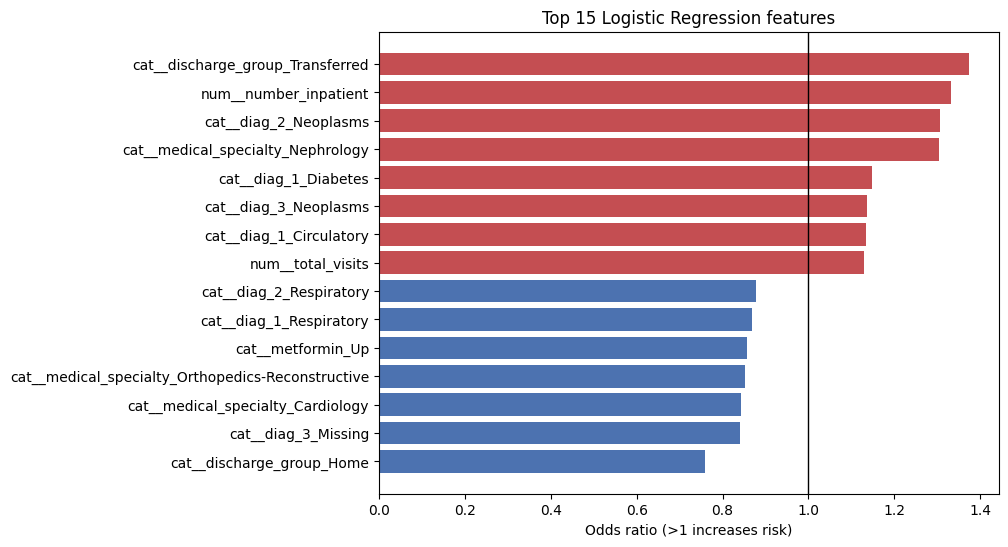

,feature,odds_ratio
86,cat__discharge_group_Home,0.759787
58,cat__diag_3_Missing,0.841008
22,cat__medical_specialty_Cardiology,0.842377
29,cat__medical_specialty_Orthopedics-Reconstructive,0.852080
74,cat__metformin_Up,0.856295
42,cat__diag_1_Respiratory,0.869048
52,cat__diag_2_Respiratory,0.878396
13,num__total_visits,1.130410
33,cat__diag_1_Circulatory,1.133750
60,cat__diag_3_Neoplasms,1.137222


In [5]:
best_lr = lr_search.best_estimator_
names = best_lr.named_steps['pre'].get_feature_names_out()
coefs = best_lr.named_steps['clf'].coef_[0]

odds = pd.DataFrame({'feature': names, 'odds_ratio': np.exp(coefs)})
odds['effect'] = np.abs(np.log(odds['odds_ratio']))
top = odds.sort_values('effect', ascending=False).head(15).sort_values('odds_ratio')

plt.figure(figsize=(8, 6))
plt.barh(top['feature'], top['odds_ratio'],
         color=np.where(top['odds_ratio'] > 1, '#c44e52', '#4c72b0'))
plt.axvline(1, color='black', linewidth=1)
plt.xlabel('Odds ratio (>1 increases risk)')
plt.title('Top 15 Logistic Regression features')
plt.savefig(FIG + '03_lr_odds.png', dpi=150, bbox_inches='tight')
plt.show()
top[['feature', 'odds_ratio']]

In [6]:
l1_model = clone(best_lr).set_params(clf__penalty='l1', clf__solver='saga', clf__max_iter=2000)
l1_model.fit(X_train, y_train)
zero = (l1_model.named_steps['clf'].coef_[0] == 0).sum()
print(f'L1 set {zero} of {len(names)} coefficients exactly to zero')

L1 set 54 of 90 coefficients exactly to zero


In [8]:
oof_lr = cross_val_predict(best_lr, X_train, y_train, groups=g_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
lr_threshold, lr_f1 = best_f1_threshold(y_train, oof_lr)
print(f'Chosen threshold: {lr_threshold:.3f} (OOF F1 = {lr_f1:.3f})')

Chosen threshold: 0.528 (OOF F1 = 0.269)


In [9]:
joblib.dump({'model': best_lr, 'threshold': lr_threshold,'refit_time': lr_search.refit_time_}, '../models/linearReg.joblib')

['../models/linearReg.joblib']